# 2.0a Superseded design: the curve-based critical-point label (2022 only)
**Previous design / superseded decision.** Kept for reproducibility of the disclosure in the paper (Section 3.4) and the decision log (*Original label fails, 2022*, *Label audit, 2022*). It is not part of the final project path, which is `../2.0-anh-labels.ipynb`.

The original design defined the label from each district's 2022 flow-occupancy curve: 0.5-point occupancy bins, median flow per bin, "capacity flow" = highest median flow among usable bins (≥ 100 slots, consecutive from the lowest bin), critical occupancy = first bin reaching 95% of it, and a district studied only if the curve showed a supported peak followed by falling flow. These rules were written before any curve was drawn. Result: no district passed. Among the 13 districts the procedure could evaluate, no sufficiently supported falling branch was identified; for 7 districts it was inconclusive, because their sparse lowest bin stopped the run of usable bins. Section 6 checks that this was not an implementation or data error. The project then dropped the physical critical-point interpretation instead of weakening the rule. The outputs below are those of the 2026-10-26 run.

In [1]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import polars as pl

from madrid_congestion.config import DISTRICT_MINIMUM, FIGURES_DIR, PROCESSED_DATA_DIR, SLOT
from madrid_congestion.districts import PANEL_PATH

BIN_WIDTH = 0.5  # occupancy points per bin (pragmatic: fine relative to the 1-point tolerance)
MIN_BIN_SLOTS = 100  # a usable bin holds at least this many valid slots
CRITERIA = {"q95": 0.95, "q90": 0.90}  # share of capacity flow that marks the critical occupancy; q95 main, q90 sensitivity
PEAK_TAIL_BINS = 3  # eligibility: the flow peak must not lie in the last 3 usable bins
LAST_BIN_MAX = 0.90  # eligibility: flow in the last usable bin is at most 90% of the peak
RESAMPLES = 200  # day resamples for the stability report
TOLERANCE = 1.0  # occupancy points: a resample is close if within this distance of the full-data value
STABLE_SHARE = 0.90  # stable if at least this share of resamples is close
SEED = 2022  # fixed seed for the day resamples

series = pl.read_parquet(PROCESSED_DATA_DIR / "district-series-2022.parquet")
panel_sizes = pl.read_parquet(PANEL_PATH).group_by("distrito").agg(panel_sensors=pl.len())
valid = series.filter(pl.col("valid_slot")).with_columns(
    bin_index=(pl.col("occupancy") / BIN_WIDTH).floor().cast(pl.Int32),  # bin lower edge = bin_index * BIN_WIDTH
    day=pl.col("slot_start").dt.date(),
)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pl.Config.set_tbl_rows(-1)
print(f"{valid.height:,} valid district slots of {series.height:,}")

2026-10-26 09:53:16.002 | INFO     | madrid_congestion.config:<module>:12 - PROJ_ROOT path is: E:\Madrid-traffic-ageing_Advanced project\madrid-congestion


617,514 valid district slots of 700,620


## 2. Curves and usable bins

In [2]:
def bin_curve(slots: pl.DataFrame) -> pl.DataFrame:
    # Per district and occupancy bin: the number of valid slots and their median flow.
    return (
        slots.group_by("distrito", "bin_index")
        .agg(slots=pl.len(), median_flow=pl.col("flow").median())
        .sort("distrito", "bin_index")
    )


def usable_bins(curve: pl.DataFrame) -> pl.DataFrame:
    # Bins from each district's lowest bin upwards, without gaps, stopping before the first bin with < MIN_BIN_SLOTS.
    return (
        curve.sort("distrito", "bin_index")
        .with_columns(
            in_run=(pl.col("bin_index") - pl.col("bin_index").min().over("distrito") == pl.int_range(pl.len()).over("distrito"))
            & (pl.col("slots") >= MIN_BIN_SLOTS)
        )
        .filter(pl.col("in_run").cast(pl.Int8).cum_min().over("distrito") == 1)
        .drop("in_run")
    )


curve = bin_curve(valid)
usable = usable_bins(curve)
usable.group_by("distrito").agg(usable_bins=pl.len(), top_edge=(pl.col("bin_index").max() + 1) * BIN_WIDTH).sort("distrito")

distrito,usable_bins,top_edge
i64,u32,f64
2,29,14.5
3,31,15.5
4,33,16.5
5,35,17.5
6,25,12.5
7,29,14.5
8,25,12.5
13,29,14.5
14,27,13.5


## 3. Capacity flow, critical occupancy and eligibility

In [3]:
def critical_points(usable: pl.DataFrame, share: float) -> pl.DataFrame:
    # Capacity flow = highest median flow among usable bins; critical occupancy = lower edge of the
    # first usable bin whose median flow reaches `share` of it.
    return (
        usable.with_columns(capacity_flow=pl.col("median_flow").max().over("distrito"))
        .filter(pl.col("median_flow") >= share * pl.col("capacity_flow"))
        .group_by("distrito")
        .agg(capacity_flow=pl.col("capacity_flow").first(), critical_occupancy=pl.col("bin_index").min() * BIN_WIDTH)
        .sort("distrito")
    )


def eligibility(usable: pl.DataFrame) -> pl.DataFrame:
    # The fixed eligibility rule. "Every used bin has >= 100 slots" holds by construction of the usable bins.
    shape = (
        usable.sort("distrito", "bin_index")
        .group_by("distrito", maintain_order=True)
        .agg(
            usable_bins=pl.len(),
            peak_position=pl.col("median_flow").arg_max(),
            peak_flow=pl.col("median_flow").max(),
            last_flow=pl.col("median_flow").last(),
        )
    )
    return (
        shape.join(panel_sizes, on="distrito")
        .with_columns(
            enough_sensors=pl.col("panel_sensors") >= DISTRICT_MINIMUM,
            peak_not_at_end=pl.col("peak_position") < pl.col("usable_bins") - PEAK_TAIL_BINS,
            falls_after_peak=pl.col("last_flow") <= LAST_BIN_MAX * pl.col("peak_flow"),
        )
        .with_columns(eligible=pl.col("enough_sensors") & pl.col("peak_not_at_end") & pl.col("falls_after_peak"))
    )


points = critical_points(usable, CRITERIA["q95"]).join(
    critical_points(usable, CRITERIA["q90"]).select("distrito", critical_occupancy_q90=pl.col("critical_occupancy")),
    on="distrito",
)
summary = eligibility(usable).join(points, on="distrito").sort("distrito")
print(f"eligible: {summary['eligible'].sum()} of {summary.height} districts")
summary

eligible: 0 of 13 districts


distrito,usable_bins,peak_position,peak_flow,last_flow,panel_sensors,enough_sensors,peak_not_at_end,falls_after_peak,eligible,capacity_flow,critical_occupancy,critical_occupancy_q90
i64,u32,u32,f64,f64,u32,bool,bool,bool,bool,f64,f64,f64
2,29,28,905.74714,905.74714,83,true,false,false,false,905.74714,12.0,10.0
3,31,28,919.253333,917.027027,78,true,false,false,false,919.253333,13.0,11.5
4,33,31,1008.209677,1005.722222,128,true,false,false,false,1008.209677,13.5,11.0
5,35,34,910.352273,910.352273,181,true,false,false,false,910.352273,16.0,13.0
6,25,24,803.60759,803.60759,139,true,false,false,false,803.60759,11.0,9.5
7,29,28,986.376147,986.376147,113,true,false,false,false,986.376147,11.5,9.5
8,25,24,510.025641,510.025641,299,true,false,false,false,510.025641,11.5,10.0
13,29,28,563.043103,563.043103,128,true,false,false,false,563.043103,11.5,10.5
14,27,26,558.398077,558.398077,66,true,false,false,false,558.398077,11.5,10.0


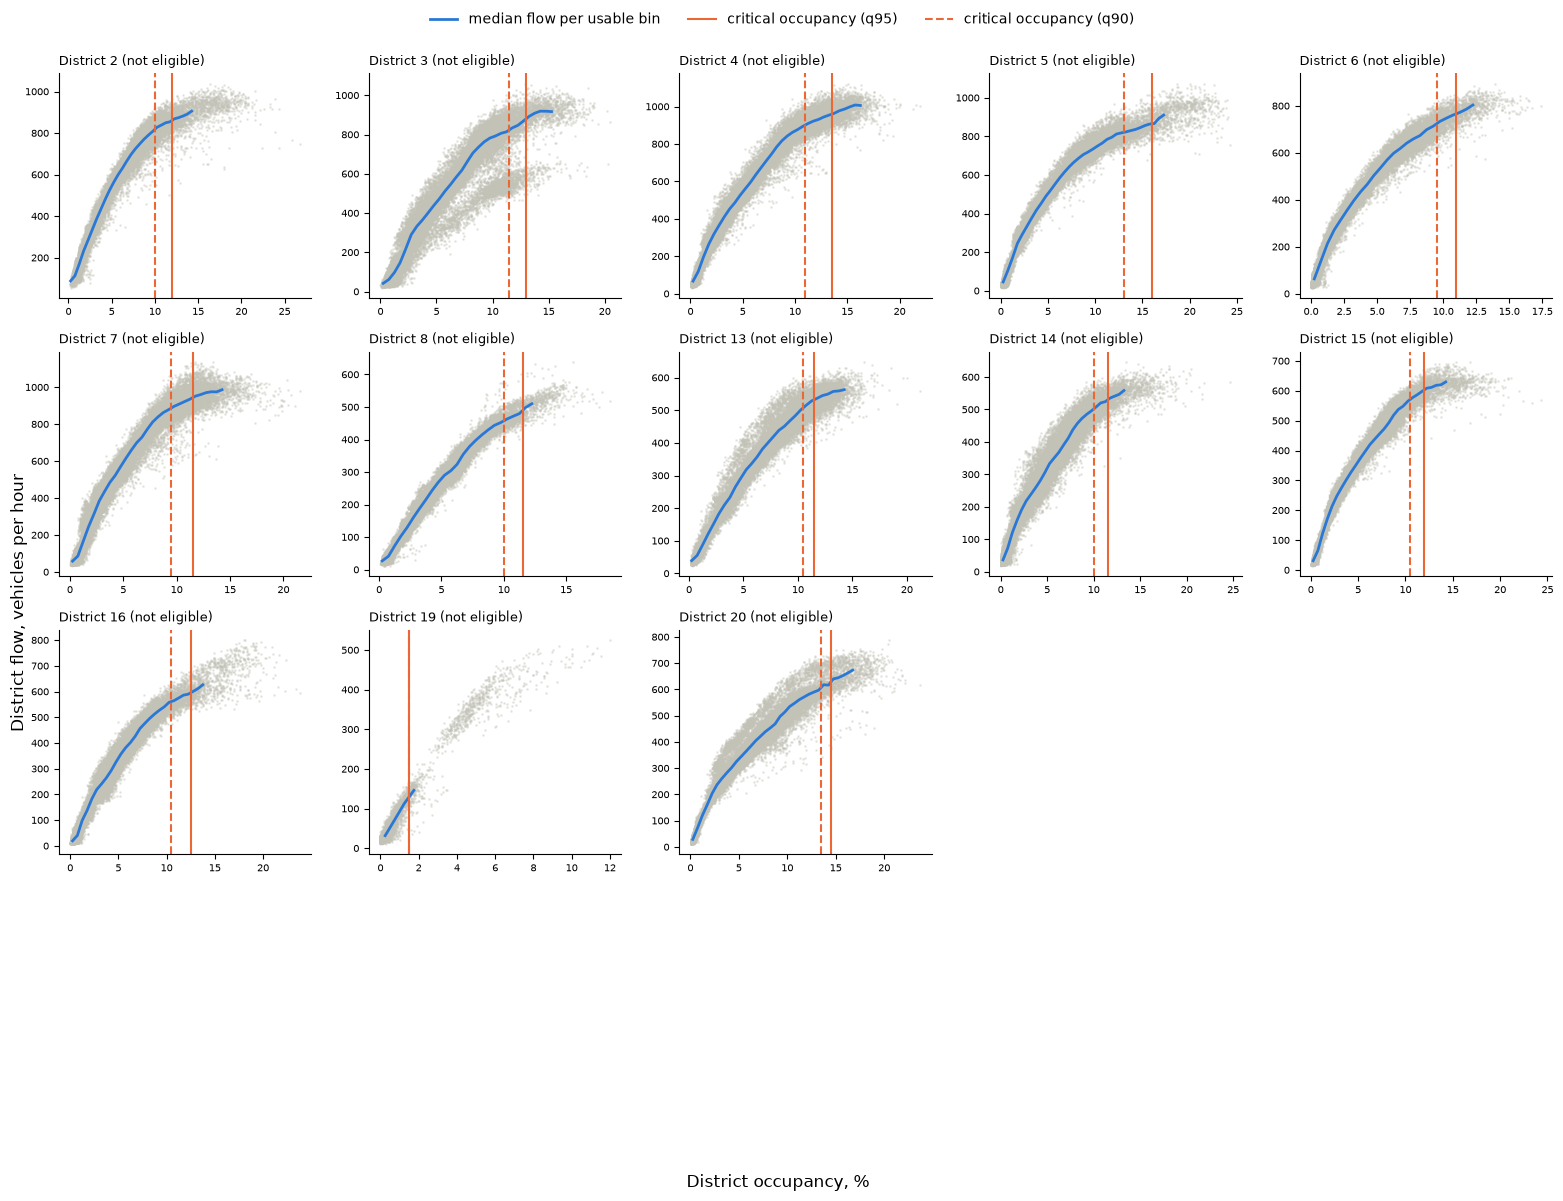

In [4]:
fig, axes = plt.subplots(4, 5, figsize=(16, 12))
for ax, row in zip(axes.flat, summary.iter_rows(named=True)):
    district = row["distrito"]
    slots = valid.filter(pl.col("distrito") == district)
    bins = usable.filter(pl.col("distrito") == district)
    ax.scatter(slots["occupancy"], slots["flow"], s=1, color="#c3c2b7", alpha=0.3, rasterized=True)
    ax.plot((bins["bin_index"] + 0.5) * BIN_WIDTH, bins["median_flow"], color="#2a78d6", lw=2)
    ax.axvline(row["critical_occupancy"], color="#eb6834", lw=1.5)
    ax.axvline(row["critical_occupancy_q90"], color="#eb6834", lw=1.5, ls="--")
    ax.set_title(f"District {district}" + ("" if row["eligible"] else " (not eligible)"), loc="left", fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=7)
fig.supxlabel("District occupancy, %")
fig.supylabel("District flow, vehicles per hour")
fig.legend(
    [Line2D([], [], color="#2a78d6", lw=2), Line2D([], [], color="#eb6834", lw=1.5), Line2D([], [], color="#eb6834", lw=1.5, ls="--")],
    ["median flow per usable bin", "critical occupancy (q95)", "critical occupancy (q90)"],
    loc="upper center", ncol=3, frameon=False,
)
fig.tight_layout(rect=(0, 0, 1, 0.97))
for ax in axes.flat[summary.height:]:  # 13 districts on a 4 x 5 grid: hide the empty panels
    ax.set_visible(False)
fig.savefig(FIGURES_DIR / "rejected-label-curves-2022.png", dpi=150)  # evidence for the rejected label, not a report figure


In [5]:
missing = sorted(set(panel_sizes["distrito"]) - set(usable["distrito"]))
print(missing)
curve.filter(pl.col("distrito").is_in(missing)).group_by("distrito", maintain_order=True).head(6)

[1, 9, 10, 11, 12, 17, 18]


distrito,bin_index,slots,median_flow
i64,i32,u32,f64
1,2,53,100.466667
1,3,405,112.557143
1,4,858,131.332937
1,5,768,155.545666
1,6,994,163.210368
1,7,1118,186.727619
9,0,1,29.076923
9,1,226,54.47973
9,2,989,71.578947


## 6. Integrity audit of the original label (2022 only)
Checks whether the zero-eligible result comes from an implementation or data problem before the label is replaced. If a bug is found, it is fixed and the original rule is rerun. The rules are not weakened to recover a falling branch.

In [6]:
from madrid_congestion.districts import VALID_READING, months_of, slot_rows

panel = pl.read_parquet(PANEL_PATH)
duplicates = series.select(pl.struct("distrito", "slot_start").is_duplicated().sum()).item()
edges_ok = valid.select(
    ((pl.col("bin_index") * BIN_WIDTH <= pl.col("occupancy")) & (pl.col("occupancy") < (pl.col("bin_index") + 1) * BIN_WIDTH)).all()
).item()
counts_ok = curve["slots"].sum() == valid.height

check = valid.filter(pl.col("distrito") == 15)  # largest district, median recomputed with numpy
medians_ok = all(
    abs(float(np.median(check.filter(pl.col("bin_index") == b)["flow"].to_numpy())) - m) < 1e-9
    for b, m in curve.filter(pl.col("distrito") == 15).select("bin_index", "median_flow").iter_rows()
)

march = (  # district means recomputed from sensor readings for one month
    slot_rows("2022-03").join(panel.select("id", "distrito"), on="id").filter(VALID_READING)
    .group_by("distrito", "slot_start").agg(occupancy_check=pl.col("ocupacion").mean(), sensors_check=pl.len())
)
averaging = series.join(march, on=["distrito", "slot_start"]).select(
    max_occupancy_difference=(pl.col("occupancy") - pl.col("occupancy_check")).abs().max(),
    sensors_match=(pl.col("sensors") == pl.col("sensors_check")).all(),
)
print(f"duplicate district slots: {duplicates}, bin edges ok: {edges_ok}, counts ok: {counts_ok}, medians ok: {medians_ok}")
averaging

duplicate district slots: 0, bin edges ok: True, counts ok: True, medians ok: True


max_occupancy_difference,sensors_match
f64,bool
0.0,true


In [7]:
# Invalid slots still carry a partial mean when some sensors reported; it is noisier (fewer sensors), so read with care.
partial = series.filter(pl.col("sensors") > 0)
by_band = (
    partial.with_columns(band=(pl.col("occupancy") / 2.5).floor() * 2.5)  # 2.5-point bands, for a readable table
    .group_by("band").agg(slots=pl.len(), valid_share=pl.col("valid_slot").mean()).sort("band")
)
edge = usable.group_by("distrito").agg(top_edge=(pl.col("bin_index").max() + 1) * BIN_WIDTH)
above_edge = (
    partial.join(edge, on="distrito")
    .group_by("distrito")
    .agg(
        valid_share_all=pl.col("valid_slot").mean(),
        slots_above_edge=(pl.col("occupancy") >= pl.col("top_edge")).sum(),
        valid_share_above_edge=pl.col("valid_slot").filter(pl.col("occupancy") >= pl.col("top_edge")).mean(),
    )
    .sort("distrito")
)
display(by_band)
above_edge

band,slots,valid_share
f64,u32,f64
0.0,205561,0.837299
2.5,138228,0.899319
5.0,124562,0.925836
7.5,111738,0.943251
10.0,59622,0.949968
12.5,23481,0.954091
15.0,12718,0.959585
17.5,6269,0.967459
20.0,2522,0.961538


distrito,valid_share_all,slots_above_edge,valid_share_above_edge
i64,f64,u32,f64
2,0.851199,830,0.906024
3,0.96051,317,0.987382
4,0.975354,164,0.963415
5,0.945121,606,0.99505
6,0.965292,256,1.0
7,0.97079,371,1.0
8,0.905427,453,0.728477
13,0.977734,190,0.989474
14,0.944613,507,0.998028


In [8]:
# Diagnostic split read off the figure, not a rule: occupancy 7-13%, lower cloud = flow below 650 vehicles per hour.
d3 = valid.filter((pl.col("distrito") == 3) & pl.col("occupancy").is_between(7, 13)).with_columns(
    lower_cloud=pl.col("flow") < 650,
    month=pl.col("slot_start").dt.month(),
    hour=pl.col("slot_start").dt.hour(),
    weekday=pl.col("slot_start").dt.weekday(),
)
for key in ("month", "hour", "weekday"):
    display(d3.group_by(key).agg(slots=pl.len(), lower_share=pl.col("lower_cloud").mean()).sort(key))
display(d3.group_by("lower_cloud").agg(slots=pl.len(), median_sensors=pl.col("sensors").median(),
                                       min_sensors=pl.col("sensors").min(), max_sensors=pl.col("sensors").max()))

keys = d3.select("slot_start", "lower_cloud")
panel3 = panel.filter(pl.col("distrito") == 3).select("id")
reports = pl.concat([
    slot_rows(month).join(panel3, on="id", how="semi").filter(VALID_READING)
    .join(keys, on="slot_start").select("id", "lower_cloud")
    for month in months_of(2022)
])
composition = (  # share of each cloud's slots in which a panel sensor has a valid reading
    reports.group_by("id", "lower_cloud").agg(n=pl.len())
    .join(keys.group_by("lower_cloud").agg(total=pl.len()), on="lower_cloud")
    .with_columns(share=pl.col("n") / pl.col("total"))
    .pivot(on="lower_cloud", index="id", values="share")
    .fill_null(0)
    .with_columns(difference=pl.col("true") - pl.col("false"))
    .sort(pl.col("difference").abs(), descending=True)
)
composition.head(10)

month,slots,lower_share
i8,u32,f64
1,1084,0.361624
2,1197,0.510443
3,1257,0.389021
4,1007,0.252234
5,1127,0.19787
6,1234,0.168558
7,1016,0.148622
8,195,0.758974
9,1195,0.105439


hour,slots,lower_share
i8,u32,f64
0,4,1.0
7,500,0.116
8,441,0.213152
9,563,0.223801
10,914,0.229759
11,1049,0.27836
12,1148,0.285714
13,1194,0.236181
14,1059,0.220963


weekday,slots,lower_share
i8,u32,f64
1,2069,0.187047
2,2183,0.23912
3,2205,0.165533
4,2222,0.20162
5,2487,0.196622
6,963,0.542056
7,627,0.76555


lower_cloud,slots,median_sensors,min_sensors,max_sensors
bool,u32,f64,u32,u32
false,9543,75.0,45,78
true,3213,48.0,39,78


id,false,true,difference
i32,f64,f64,f64
4243,0.968668,0.341737,-0.626931
3883,0.990045,0.420479,-0.569566
3862,0.990045,0.420479,-0.569566
3869,0.990464,0.421102,-0.569362
4191,0.990464,0.421102,-0.569362
3864,0.99015,0.420791,-0.569359
4192,0.990359,0.421413,-0.568946
3886,0.988159,0.420168,-0.567991
3884,0.988683,0.420791,-0.567892


In [9]:
display(
    curve.filter(pl.col("distrito").is_in(missing)).group_by("distrito", maintain_order=True).agg(
        lowest_bin_slots=pl.col("slots").first(),
        first_dense_edge=pl.col("bin_index").filter(pl.col("slots") >= MIN_BIN_SLOTS).min() * BIN_WIDTH,
        valid_slots=pl.col("slots").sum(),
    )
)
series.group_by("distrito").agg(
    valid_slots=pl.col("valid_slot").sum(),
    valid_share=pl.col("valid_slot").mean(),
    valid_share_07_19=pl.col("valid_slot").filter(pl.col("slot_start").dt.hour().is_between(7, 19)).mean(),
    occupancy_p95=pl.col("occupancy").filter(pl.col("valid_slot")).quantile(0.95),
    flow_p95=pl.col("flow").filter(pl.col("valid_slot")).quantile(0.95),
).sort("distrito")

distrito,lowest_bin_slots,first_dense_edge,valid_slots
i64,u32,f64,u32
1,53,1.5,30244
9,1,0.5,29841
10,2,0.5,33505
11,1,0.5,33417
12,14,0.5,33614
17,46,0.5,33586
18,48,0.5,30056


distrito,valid_slots,valid_share,valid_share_07_19,occupancy_p95,flow_p95
i64,u32,f64,f64,f64,f64
1,30244,0.86335,0.872076,18.542553,687.029703
2,29277,0.835745,0.871338,12.243902,875.6625
3,33055,0.943593,0.968072,12.266667,876.684211
4,33559,0.95798,0.971444,13.64,977.047244
5,32515,0.928178,0.950474,13.80814,845.034682
6,33207,0.947932,0.95843,9.537879,731.080882
7,33401,0.95347,0.967071,12.131313,972.342593
8,31163,0.889584,0.961749,9.814035,455.73064
9,29841,0.851846,0.971812,12.587302,617.76378
